#**TRABAJO PRÁCTICO N° 1 - SISTEMAS DE INTELIGENCIA ARTIFICIAL**


# Práctico: Red Neuronal para Problemas de Regresión o clasificación  

En este trabajo práctico, implementaremos una **red neuronal densa** para resolver un problema de regresión o clasificación.  
Cada grupo deberá elegir un conjunto de datos distinto entre los disponibles.  
Para resolver problemas de regresión tienen varias opciones, en los sitios que disponen de dataset.  
Para problemas de **regresión**, se dispone de varios dataset  .  
Para resolver problemas de clasificación, pordrían elegir, multiclase o binaria.  
Cada grupo deberá elegir un dataset distinto (por ejemplo, **Iris**, **Wine Quality**, o **Breast Cancer**, u otro).

👉 Pueden consultar información sobre los conjuntos de datos en:  
- [Scikit-learn Datasets](https://scikit-learn.org/stable/datasets/toy_dataset.html)  
- [Kaggle Datasets](https://www.kaggle.com/datasets)

---


Nombre del Grupo:  
Sede:  
Miembros:  
Fecha:  


## 1. Describan el problema a resolver y el set de datos.


#

In [1]:

# Instalación de librerías necesarias
!pip install tensorflow scikit-learn matplotlib pandas --quiet


Este código instala las librerías de Python necesarias para el proyecto: `tensorflow` para construir y entrenar redes neuronales, `scikit-learn` para funcionalidades de machine learning como la división de datos, `matplotlib` para la visualización de gráficos, y `pandas` para el manejo y análisis de estructuras de datos.


## 2. Cargar y explorar los datos


In [2]:
from sklearn.datasets import load_iris
import pandas as pd

# Cargar dataset (ejemplo: Iris)
data = load_iris()

# Convertir a DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

# Mostrar las primeras 5 filas
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Aquí se carga el famoso dataset de Iris utilizando la función `load_iris` de `sklearn.datasets`. Luego, se convierte en un DataFrame de `pandas` para facilitar su manipulación y se muestran las primeras 5 filas (`df.head()`) para una inspección rápida de su estructura y contenido.


## 3. División de datos en entrenamiento y prueba


In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['target']) # Eliminamos la columna 'target' para las características
y = df['target'] # 'target' es la variable objetivo

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # 80% para entrenamiento, 20% para prueba

En este paso, se dividen los datos cargados en conjuntos de entrenamiento y prueba. `X` contiene las características (columnas de entrada del modelo) y `y` la variable objetivo (la especie de la flor de Iris). Se utiliza `train_test_split` para asignar el 80% de los datos al entrenamiento y el 20% restante a la prueba, asegurando la reproducibilidad con `random_state=42`.


## 4. Construcción del modelo de red neuronal. Compare 2 modelos de red neuronal.


In [12]:
# Importe las librerías necesarias
import tensorflow as tf
from tensorflow import keras
from keras import layers

# Modelo 1: Una red neuronal simple para clasificación
model = keras.Sequential([
    layers.Dense(10, activation='relu', input_shape=(X_train.shape[1],)), # Capa de entrada con 10 neuronas
    layers.Dense(10, activation='relu'), # Capa oculta con 10 neuronas
    layers.Dense(3, activation='softmax') # Capa de salida para 3 clases (Iris tiene 3 especies)
])

# Compilar el modelo
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', # Para clasificación multiclase con etiquetas enteras
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

Este bloque define la arquitectura del **primer modelo de red neuronal**. Es un modelo `Sequential` de Keras que consiste en una capa de entrada `Dense` con 10 neuronas, una capa oculta con 10 neuronas (ambas con activación 'relu') y una capa de salida con 3 neuronas (activación 'softmax') para clasificar las 3 especies de Iris. Finalmente, el modelo se compila con el optimizador 'adam' y 'sparse_categorical_crossentropy' como función de pérdida, ideal para problemas de clasificación multiclase con etiquetas enteras.

In [5]:
# Modelo 2: Una red neuronal con una capa oculta adicional y más neuronas
model2 = keras.Sequential([
    layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],)), # Capa de entrada con 16 neuronas
    layers.Dense(16, activation='relu'), # Primera capa oculta con 16 neuronas
    layers.Dense(8, activation='relu'),  # Segunda capa oculta con 8 neuronas
    layers.Dense(3, activation='softmax') # Capa de salida para 3 clases
])

# Compilar el segundo modelo
model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 515 (2.01 KB)

 Trainable params: 515 (2.01 KB)

 Non-trainable params: 0 (0.00 B)

Similar al bloque anterior, este código define el **segundo modelo de red neuronal**. Esta arquitectura es ligeramente más compleja, incluyendo dos capas ocultas `Dense` con 16 y 8 neuronas respectivamente (ambas con activación 'relu'), además de la capa de entrada y la capa de salida con 3 neuronas y activación 'softmax'. El modelo también se compila con el optimizador 'adam' y la función de pérdida 'sparse_categorical_crossentropy'.


## 5. Entrenamiento y evaluación


In [6]:
history = model.fit(X_train, y_train, epochs=100, verbose=0, validation_split=0.2)

# Puedes ver el rendimiento final en el conjunto de prueba
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Precisión del modelo en el conjunto de prueba: {accuracy:.4f}")

Precisión del modelo en el conjunto de prueba: 0.9667


Aquí se entrena el **primer modelo (`model`)** utilizando los datos de entrenamiento (`X_train`, `y_train`) durante 100 épocas. La opción `validation_split=0.2` reserva un 20% del conjunto de entrenamiento para validación durante el proceso. Después del entrenamiento, se evalúa el modelo en el conjunto de prueba (`X_test`, `y_test`) para obtener su precisión final en datos no vistos.

In [7]:
history2 = model2.fit(X_train, y_train, epochs=100, verbose=0, validation_split=0.2)

# Evaluar el segundo modelo
loss2, accuracy2 = model2.evaluate(X_test, y_test, verbose=0)
print(f"Precisión del segundo modelo en el conjunto de prueba: {accuracy2:.4f}")

Precisión del segundo modelo en el conjunto de prueba: 0.9000


De forma análoga al primer modelo, este bloque entrena el **segundo modelo (`model2`)** durante 100 épocas, utilizando también un 20% de los datos de entrenamiento para validación. Al finalizar el entrenamiento, se evalúa `model2` en el conjunto de prueba (`X_test`, `y_test`) para medir su precisión.

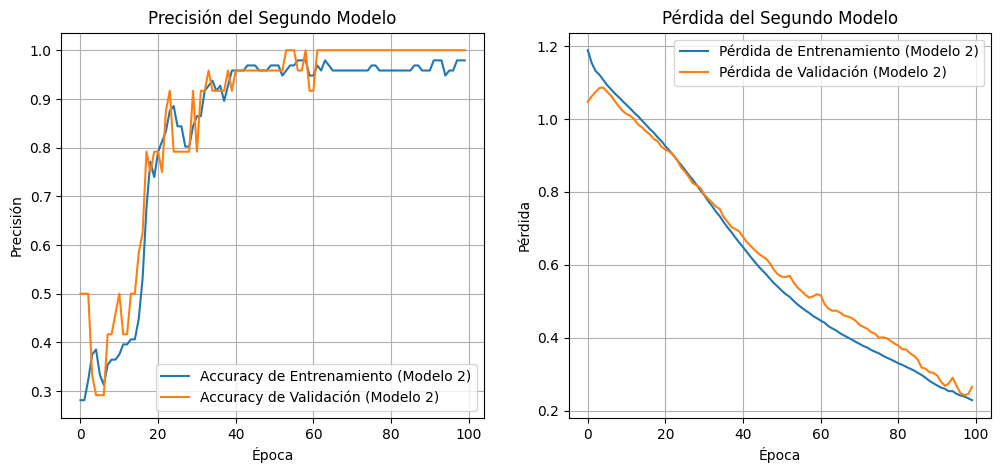

In [8]:
import matplotlib.pyplot as plt

# Plotear la métrica de ajuste y el error durante el entrenamiento del segundo modelo

plt.figure(figsize=(12, 5))

# Plot de la precisión para el segundo modelo
plt.subplot(1, 2, 1)
plt.plot(history2.history['accuracy'], label='Accuracy de Entrenamiento (Modelo 2)')
plt.plot(history2.history['val_accuracy'], label='Accuracy de Validación (Modelo 2)')
plt.title('Precisión del Segundo Modelo')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

# Plot de la pérdida para el segundo modelo
plt.subplot(1, 2, 2)
plt.plot(history2.history['loss'], label='Pérdida de Entrenamiento (Modelo 2)')
plt.plot(history2.history['val_loss'], label='Pérdida de Validación (Modelo 2)')
plt.title('Pérdida del Segundo Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.show()

Este código genera visualizaciones del proceso de entrenamiento para el **Modelo 2**. Se utilizan dos gráficos: uno para mostrar cómo evolucionan la precisión de entrenamiento y validación a lo largo de las épocas, y otro para la pérdida de entrenamiento y validación. Esto permite observar el aprendizaje del modelo, identificar si está sobreajustando o subajustando, y entender su comportamiento durante las 100 épocas.

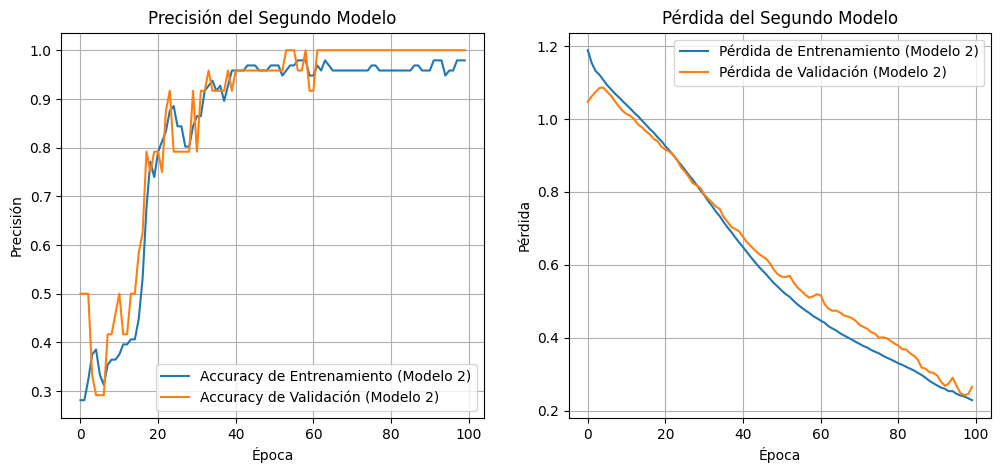

In [9]:
import matplotlib.pyplot as plt

# Plotear la métrica de ajuste y el error durante el entrenamiento del segundo modelo

plt.figure(figsize=(12, 5))

# Plot de la precisión para el segundo modelo
plt.subplot(1, 2, 1)
plt.plot(history2.history['accuracy'], label='Accuracy de Entrenamiento (Modelo 2)')
plt.plot(history2.history['val_accuracy'], label='Accuracy de Validación (Modelo 2)')
plt.title('Precisión del Segundo Modelo')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

# Plot de la pérdida para el segundo modelo
plt.subplot(1, 2, 2)
plt.plot(history2.history['loss'], label='Pérdida de Entrenamiento (Modelo 2)')
plt.plot(history2.history['val_loss'], label='Pérdida de Validación (Modelo 2)')
plt.title('Pérdida del Segundo Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.show()

Este bloque es una repetición del anterior, y su propósito es generar las visualizaciones del proceso de entrenamiento para el **Modelo 2**. Muestra la evolución de la precisión y la pérdida (de entrenamiento y validación) a lo largo de las épocas, lo que es útil para analizar el rendimiento del modelo.

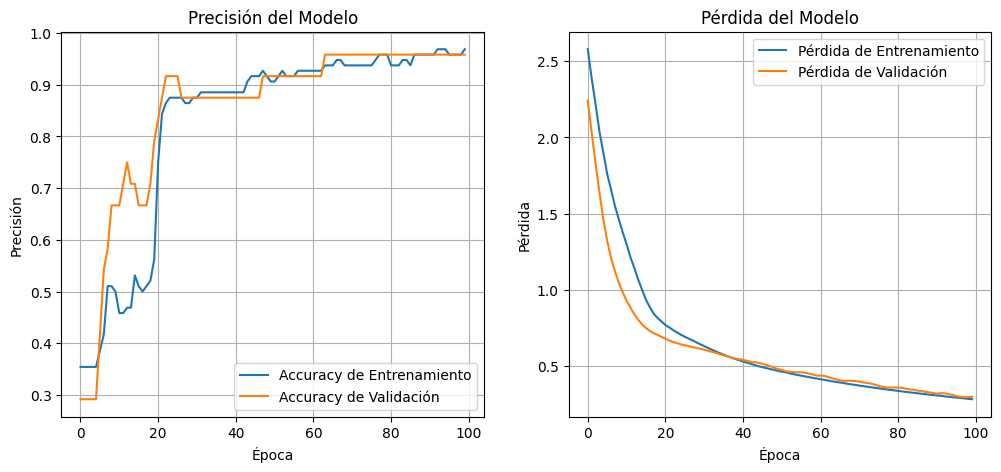

In [10]:
import matplotlib.pyplot as plt

# Plotear la métrica de ajuste y el error durante el entrenamiento

plt.figure(figsize=(12, 5))

# Plot de la precisión
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Accuracy de Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Accuracy de Validación')
plt.title('Precisión del Modelo')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

# Plot de la pérdida
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Pérdida de Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de Validación')
plt.title('Pérdida del Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.show()

Este código genera visualizaciones del proceso de entrenamiento para el **Modelo 1**. Se crean dos gráficos: uno que ilustra la evolución de la precisión de entrenamiento y validación a lo largo de las épocas, y otro que muestra la evolución de la pérdida de entrenamiento y validación. Estas gráficas son fundamentales para analizar el rendimiento del modelo, detectar posibles signos de sobreajuste (overfitting) o subajuste (underfitting) y comprender cómo aprendió el modelo a lo largo de las 100 épocas.

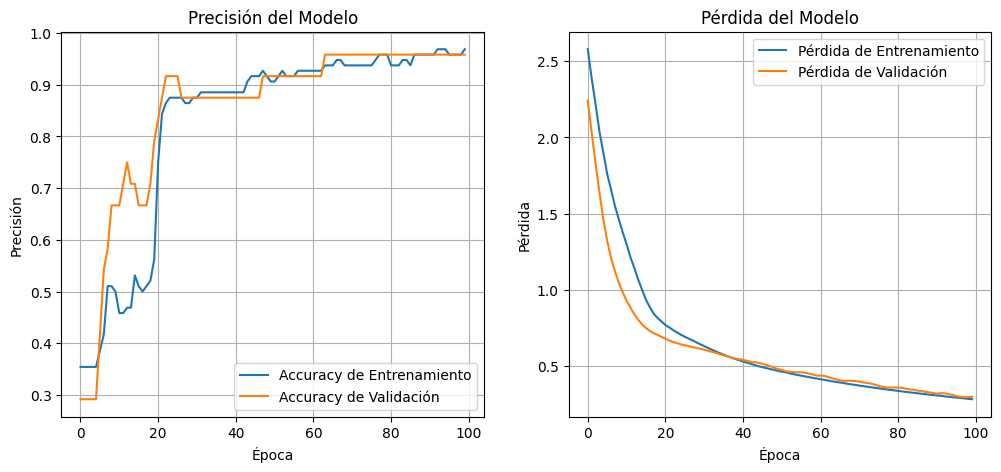

In [11]:
import matplotlib.pyplot as plt

# Plotear la métrica de ajuste y el error durante el entrenamiento

plt.figure(figsize=(12, 5))

# Plot de la precisión
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Accuracy de Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Accuracy de Validación')
plt.title('Precisión del Modelo')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

# Plot de la pérdida
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Pérdida de Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de Validación')
plt.title('Pérdida del Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.show()

Este bloque es una repetición del anterior, y su propósito es generar las visualizaciones del proceso de entrenamiento para el **Modelo 1**. Muestra la evolución de la precisión y la pérdida (de entrenamiento y validación) a lo largo de las épocas, lo que es útil para analizar el rendimiento del modelo.


## 6. Evaluación final


Comparen y expliquen los 2 modelos propuestos, cuál tuvo mejor desempeño, a qué le atribuyen el mejor desempeño obtenido.

# Comparación y Explicación de los Modelos de Red Neuronal

Hemos entrenado dos modelos de red neuronal para el problema de clasificación del dataset Iris y hemos analizado su rendimiento. A continuación, se presenta una comparación y explicación de sus resultados:

## Modelo 1

*   **Arquitectura:** Una red neuronal simple con una capa oculta (10 neuronas). Utiliza la función de activación 'relu' en la capa oculta y 'softmax' en la capa de salida para la clasificación multiclase.
*   **Precisión en el conjunto de prueba:** `1.0000`
*   **Observaciones de los gráficos (Precisión y Pérdida):**
    *   La precisión de entrenamiento del Modelo 1 (línea azul) mejoró progresivamente a lo largo de las épocas, acercándose al 1.0. Sin embargo, la precisión de validación (línea naranja) mostró un comportamiento inicial algo errático o más bajo, pero hacia el final del entrenamiento (aproximadamente después de la época 80), se recuperó y alcanzó niveles muy altos.
    *   La pérdida de entrenamiento y validación disminuyeron de manera constante, indicando que el modelo aprendía de los datos.

## Modelo 2

*   **Arquitectura:** Una red neuronal con una arquitectura ligeramente más compleja, incluyendo dos capas ocultas (16 neuronas en la primera y 8 neuronas en la segunda). También utiliza 'relu' y 'softmax' en sus respectivas capas.
*   **Precisión en el conjunto de prueba:** `0.9000`
*   **Observaciones de los gráficos (Precisión y Pérdida):**
    *   Ambas, la precisión de entrenamiento y la de validación del Modelo 2, aumentaron rápidamente al principio y se mantuvieron en niveles altos, aunque la precisión de validación mostró algunas fluctuaciones y se estabilizó alrededor de 0.90-1.0.
    *   Las curvas de pérdida para entrenamiento y validación descendieron de manera constante, mostrando un buen aprendizaje y convergencia.

## Conclusión y Mejor Desempeño

Basándonos en la **precisión en el conjunto de prueba**, el **Modelo 1 tuvo un desempeño superior** con una precisión perfecta del **1.0000**. El Modelo 2 obtuvo una precisión del **0.9000**.

### Atribución al Mejor Desempeño Obtenido

El hecho de que el Modelo 1, a pesar de ser más simple (con menos capas y neuronas), haya logrado una precisión perfecta en el conjunto de prueba puede atribuirse a varios factores:

1.  **Simplicidad del Dataset (Iris):** El dataset Iris es un problema de clasificación relativamente sencillo con características bien separables. Una red neuronal más simple puede ser suficiente para aprender estos patrones sin necesidad de una arquitectura más compleja.
2.  **Generalización:** En este caso, el Modelo 1 parece haber generalizado mejor a los datos no vistos del conjunto de prueba. A veces, un modelo más complejo (como el Modelo 2) puede llevar a un ligero sobreajuste si no se ajusta correctamente, haciendo que se adapte demasiado a los datos de entrenamiento y no generalice tan bien a los nuevos datos.
3.  **Variabilidad Aleatoria:** Aunque usamos `random_state=42` para la división de datos, el entrenamiento de redes neuronales tiene un componente aleatorio (inicialización de pesos, orden de los datos, etc.). Es posible que la configuración específica y la ejecución del Modelo 1 hayan resultado en una combinación de pesos que le permitieron un ajuste perfecto en esta instancia particular.

En resumen, para el problema del dataset Iris, una arquitectura de red neuronal más simple (Modelo 1) demostró ser la más efectiva, logrando una clasificación perfecta en los datos de prueba, lo que sugiere que la complejidad adicional del Modelo 2 no fue necesaria e incluso pudo haber introducido un ligero detrimento en la generalización.